<a href="https://colab.research.google.com/github/lisalaktionova/git-practice/blob/main/%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%22%D0%9C%D0%95%D0%92%D0%94_%D0%9B%D0%A02_24_25%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Постановка задачи


**Цель работы:** изучение основных способов визуализации табличных данных с помощью модулей `seaborn`, `plotly`, `altair`, `bokeh`.

**Краткое описание:** в лабораторной работе представлено 10 заданий на построение графиков разных видов. В каждом задании указано, каким видом графика стоит воспользоваться для визуализации данных. По каждому заданию необходимо построить график дважды: первый раз с помощью модуля `seaborn` (альтернативно можно `matplotlib` со стилями из `seaborn`), второй – с помощью `plotly`, `altair` или `bokeh` на выбор студента. Необязательно каждый раз для второго графика выбирать одну и ту же библиотеку, т.к. не все библиотеки располагают одинаковым набором графиков.

# Данные


По [ссылке](https://drive.google.com/drive/folders/1e0E4vQzaE9LBZgfzz0AzsyAXgtH0eMaP?usp=share_link) расположена таблица с информацией о песнях, исполненных на Евровидении с 2009 по 2023 год. Все задания лабораторной работы необходимо выполнять по этим данным. Данные в полном объеме можно найти [по ссылке](https://www.kaggle.com/datasets/diamondsnake/eurovision-song-contest-data).

##### **Формат данных**

```
year,country,artist_name,song_name,language,style,gender,main_singers,key,BPM,energy,danceability,happiness,loudness,acousticness,instrumentalness,liveness,speechiness,final_place
2023,Norway,Alessandra,Queen of Kings,English,Pop,Female,1,E Minor,110,36,64,23,10 dB,58,0,10,3,5
2023,Malta,The Busker,Dance (Our Own Party),English,Pop,Male,1,F Minor,103,78,70,82,6 dB,2,0,18,4,
...
```
##### **Описание полей**

- ```year``` – год;
- ```country``` – страна участника;
- ```artist_name``` – исполнитель;
- ```song_name``` – название песни;
- ```language``` – язык, на котором исполняется песня;
- ```style```	– жанр;
- ```gender``` – пол участника;
- ```main_singers``` – количество вокалистов;
- ```key```	– регистр (высота тона);
- ```BPM``` – скорость композиции в целом (количество четвертых нот в минуту);
- ```energy``` – энергичность композиции;
- ```danceability``` – танцевальность (насколько трек подходит для танцев);
- ```happiness``` – жизнерадостность;
- ```loudness``` – громкость;
- ```acousticness``` – акустичность;
- ```instrumentalness``` – инструментальность;
- ```liveness``` – живость;
- ```speechiness``` – насколько много текста;
- ```final_place``` – место в фонале.

# Практические задания

>По каждому заданию должен быть сделан вывод. Также нужно обязательно добавлять подпись графика и осей.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import altair as alt
import seaborn as sns

## Задание 1

Проведите предобработку числовых значений в датасете:
1. В столбцах `BPM`, `energy`, `danceability`, `happiness`, `acousticness`, `instrumentalness`, `liveness`, `speechiness` замените отсутствующие значения и прочерки на 0.
2. В столбце `loudness` оставьте только число без единиц измерения.
3. Во всех перечисленных в пунктах 1 и 2 столбцах преобразуйте значения в тип данных `float`.

In [19]:
# Загрузка данных
data = pd.read_csv("song_data.csv")  # укажите путь к файлу
data.sample(5)

,year,country,artist_name,song_name,language,style,gender,main_singers,key,BPM,energy,danceability,happiness,loudness,acousticness,instrumentalness,liveness,speechiness,final_place
467,2011,Sweden,Eric Saade,Popular,English,Dance,Male,1,A Major,125,96,54,49,5 dB,0,0,5,10,3.0
201,2017,Georgia,Tamara Gachechiladze,Keep the Faith,English,Pop,Female,1,G Minor,132,67,27,19,6 dB,15,0,10,6,NaN
108,2021,Switzerland,Gjon's Tears,Tout l'univers,French,Ballad,Male,1,A Minor,123,37,52,19,9 dB,83,0,15,3,3.0
48,2022,Denmark,Reddi,The Show,English,Rock,Female,1,C Major,90,80,31,21,5 dB,2,0,37,6,NaN
329,2014,Russia,Tolmachevy Sisters,Shine,English,Pop,Female,2,E Minor,120,87,63,71,5 dB,22,0,10,3,7.0


In [21]:
# Столбцы, в которых нужно заменить пропуски и прочерки на 0
cols_to_clean = ['BPM', 'energy', 'danceability', 'happiness',
                 'acousticness', 'instrumentalness', 'liveness', 'speechiness']

# Заменим прочерки и NaN (Not a Number - df пустой ячейки в pandas) на 0, преобразуем к float
data[cols_to_clean] = data[cols_to_clean].replace('-', 0).fillna(0).astype(float) # fillna(0) - заменяет NaN на 0

# Очистим столбец loudness от " dB", заменим NaN на 0, преобразуем к float
data['loudness'] = data['loudness'].astype(str).str.replace(' dB', '', regex=False).replace('-', '0') #regex-испл. регулярных выражений
data['loudness'] = data['loudness'].replace('', '0').fillna(0).astype(float)

data.sample(5)

,year,country,artist_name,song_name,language,style,gender,main_singers,key,BPM,energy,danceability,happiness,loudness,acousticness,instrumentalness,liveness,speechiness,final_place
423,2012,Ukraine,Gaitana,Be My Guest,English,Dance,Female,1,-,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,15.0
15,2023,Denmark,Reiley,Breaking My Heart,English,Pop,Male,1,D Major,194.0,75.0,59.0,57.0,5.0,5.0,0.0,10.0,36.0,NaN
129,2019,Estonia,Victor Crone,Storm,English,Pop,Male,1,D Major,128.0,59.0,62.0,29.0,5.0,5.0,0.0,8.0,3.0,20.0
87,2021,Belgium,Hooverphonic,The Wrong Place,English,Ballad,Female,1,F Major,80.0,73.0,49.0,25.0,4.0,5.0,0.0,16.0,4.0,19.0
348,2014,Belarus,Teo,Cheesecake,English,Pop,Male,1,Db Minor,95.0,80.0,80.0,89.0,4.0,18.0,0.0,7.0,7.0,16.0


## Задание 2

Покажите, какие характеристики музыки (`BPM`, `energy`, `danceability`, `happiness`, `acousticness`, `instrumentalness`, `liveness`, `speechiness`) коррелируют между собой. Для визуализации используйте диаграмму `heatmap` (корреляционная матрица).

### Seaborn

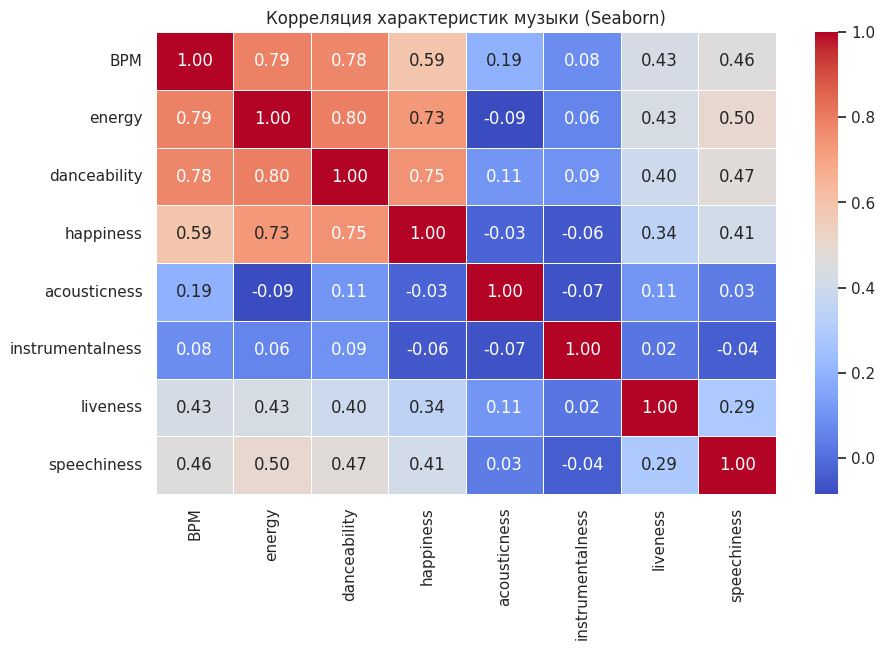

In [30]:
# Столбцы для анализа
cols_to_analyze = ['BPM', 'energy', 'danceability', 'happiness',
                   'acousticness', 'instrumentalness', 'liveness', 'speechiness']

# Корреляционная матрица
correlation_matrix = data[cols_to_analyze].corr()

# Построение heatmap с помощью Seaborn
sns.set_palette("flare")
sns.set()

plt.figure(figsize=(10, 6))  # Размер графика (в дюймах)
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', cbar=True, linewidths=0.5)
#annot-отображение числа, cbar-отображение цветовой шкалы

plt.title('Корреляция характеристик музыки (Seaborn)')
plt.show()

### Plotly

In [29]:
# Округление значений до 2 знаков после запятой
correlation_matrix = correlation_matrix.round(2)

# Построение heatmap с помощью Plotly
fig = px.imshow(correlation_matrix,
                color_continuous_scale='RdBu_r',
                title="Корреляция характеристик музыки (Plotly)",
                text_auto=True)# text_auto -добавление чисел на диаграмме

# Изменение размера графика (в пикселях)
fig.update_layout(
    width=800,  # Ширина графика
    height=600  # Высота графика
)

# Отображаем график
fig.show()

## Задание 3

Покажите на диаграмме разброса взаимосвязь между жизнерадостностью (`happiness`) и энергичностью (`energy`) композиции. Добавьте на диаграмму вспомогательные элементы (отметку средних значений, выбросов) для упрощения интерпретации визуализации.



### Seaborn

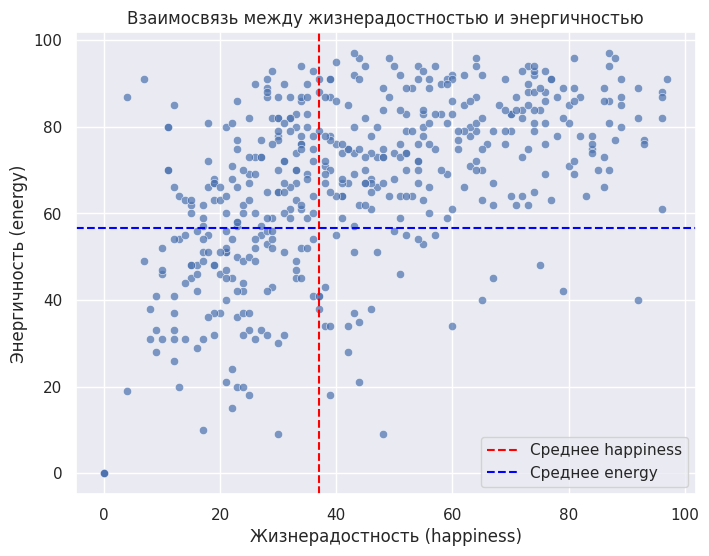

In [31]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=data, x='happiness', y='energy', alpha=0.7)

# Линии средних значений
plt.axvline(data['happiness'].mean(), color='red', linestyle='--', label='Среднее happiness')
plt.axhline(data['energy'].mean(), color='blue', linestyle='--', label='Среднее energy')

plt.title('Взаимосвязь между жизнерадостностью и энергичностью')
plt.xlabel('Жизнерадостность (happiness)')
plt.ylabel('Энергичность (energy)')
plt.legend()
plt.grid(True)
plt.show()

### Plotly

In [32]:
fig = px.scatter(data, x='happiness', y='energy', opacity=0.7)

# Добавим линии средних значений
fig.add_shape(type='line',
              x0=data['happiness'].mean(), x1=data['happiness'].mean(),
              y0=data['energy'].min(), y1=data['energy'].max(),
              line=dict(color='red', dash='dash'),
              name='Среднее happiness')

fig.add_shape(type='line',
              x0=data['happiness'].min(), x1=data['happiness'].max(),
              y0=data['energy'].mean(), y1=data['energy'].mean(),
              line=dict(color='blue', dash='dash'),
              name='Среднее energy')

fig.update_layout(title='Взаимосвязь между жизнерадостностью и энергичностью',
                  xaxis_title='Жизнерадостность (happiness)',
                  yaxis_title='Энергичность (energy)',
                  showlegend=False)
fig.show()

## Задание 4

Покажите на горизонтальной столбчатой диаграмме распределение количества треков по жанрам. Отсортируйте диаграмму по убыванию количества композиций в жанре. Выделите контрастным цветом жанр, в котором больше всего песен.

### Seaborn

<ipython-input-38-7d3d0d88fab5>:4: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




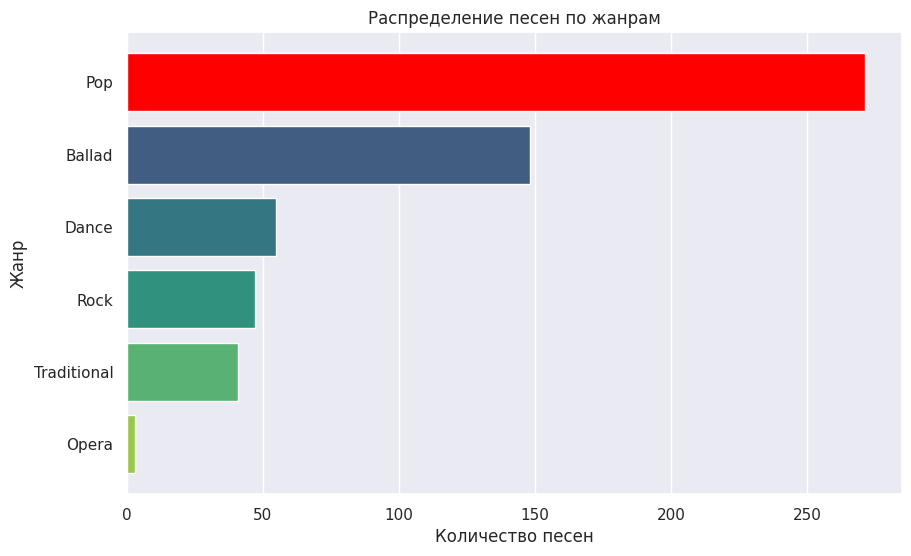

In [38]:
genre_counts = data['style'].value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(x=genre_counts.values, y=genre_counts.index, palette='viridis')

# Подсветим жанр с максимальным количеством песен
max_genre = genre_counts.idxmax()
plt.barh(y=max_genre, width=genre_counts[max_genre], color='red')

plt.title('Распределение песен по жанрам')
plt.xlabel('Количество песен')
plt.ylabel('Жанр')
plt.show()


### Plotly

In [44]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors

genre_counts = data['style'].value_counts().reset_index()
genre_counts.columns = ['genre', 'count']


# Создание градиента от красного к синему (теплый → холодный)
norm = mcolors.Normalize(vmin=0, vmax=len(genre_counts))
cmap = cm.get_cmap('coolwarm')
colors = [mcolors.to_hex(cmap(norm(i))) for i in reversed(range(len(genre_counts)))]
genre_counts['color'] = colors

# Построение графика
fig = px.bar(genre_counts, x='count', y='genre', orientation='h',
             color='color', color_discrete_map='identity')

# Инвертируем порядок оси Y (самые популярные вверху)
fig.update_layout(title='Распределение песен по жанрам',
                  xaxis_title='Количество песен',
                  yaxis_title='Жанр',
                  showlegend=False ,
    yaxis=dict(autorange='reversed'))

fig.show()

<ipython-input-44-6108eef9bd8e>:10: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.



## Задание 5

Покажите на круговой диаграмме страны, участники из которых побеждали чаще других, и в каких годах они выигрывали. Диаграмма должна быть одна.

### Seaborn

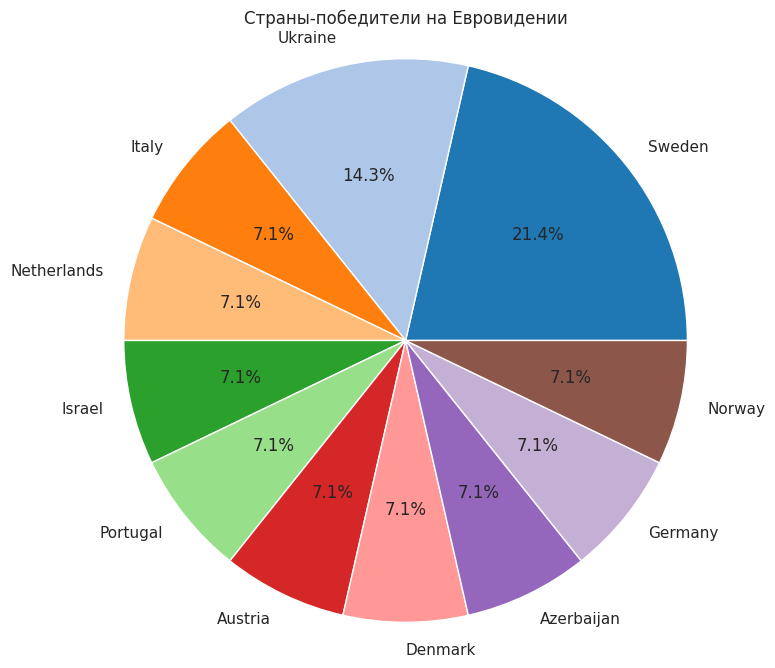

In [48]:
winners = data[data['final_place'] == 1]
country_win_counts = winners['country'].value_counts()

colors = plt.cm.tab20.colors  # палитра на 20 уникальных цветов, т.к. не хватало цветов

plt.figure(figsize=(8, 8))
plt.pie(country_win_counts, labels=country_win_counts.index, autopct='%1.1f%%', startangle=0,
        colors=colors[:len(country_win_counts)]  # применяем нужное количество цветов
        )
plt.title('Страны-победители на Евровидении')
plt.axis('equal')
plt.show()

### Plotly

In [47]:
winners = data[data['final_place'] == 1]
country_win_counts = winners['country'].value_counts().reset_index()
country_win_counts.columns = ['country', 'count']

fig = px.pie(country_win_counts, names='country', values='count',
             title='Страны-победители на Евровидении')
fig.show()

## Задание 6

На вертикальной столбчатой диаграмме с группировкой покажите количество мужчин и женщин среди участников в каждом году, представленном в датасете.

### Seaborn

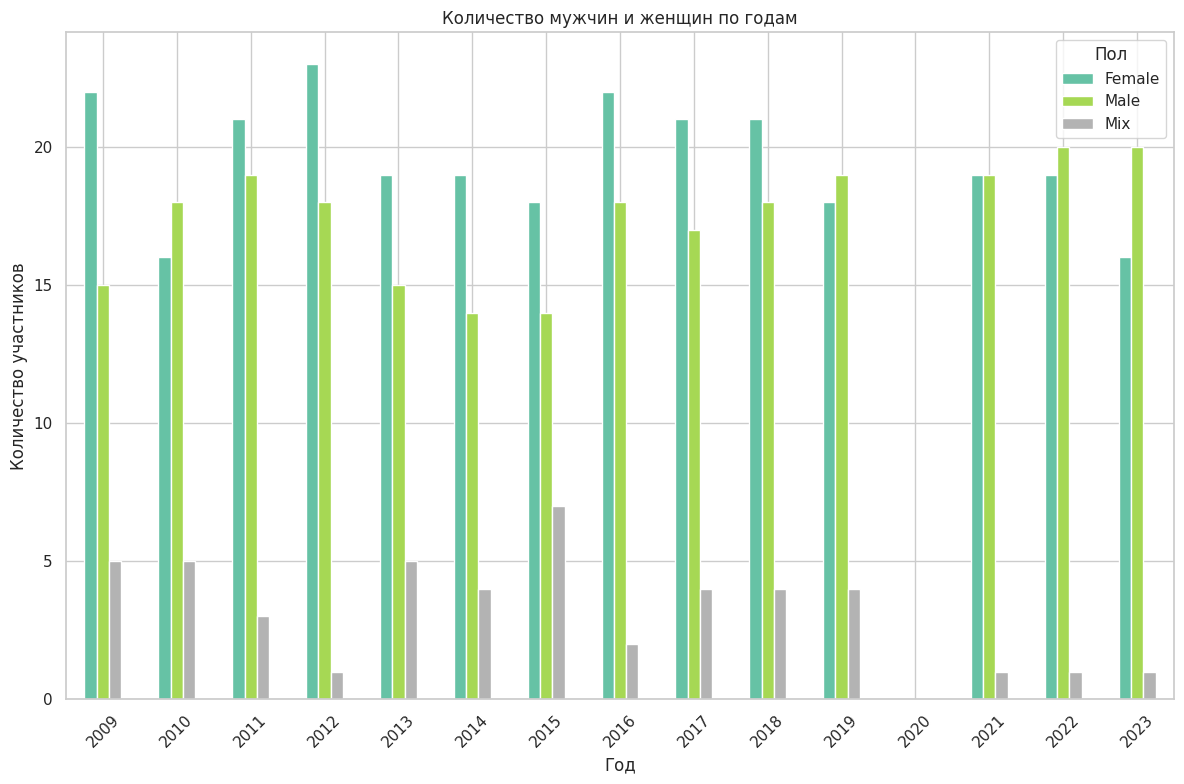

In [102]:
# Проверка наличия 2020 года
if 2020 not in gender_counts.index:
    gender_counts.loc[2020] = [0] * len(gender_counts.columns)
    gender_counts = gender_counts.sort_index()

# Построение графика с 2020 годом
gender_counts.plot(kind='bar', stacked=False, figsize=(12, 8), colormap='Set2')
plt.title('Количество мужчин и женщин по годам')
plt.xlabel('Год')
plt.ylabel('Количество участников')
plt.xticks(rotation=45)
plt.legend(title='Пол')
plt.tight_layout()
plt.show()


### Plotly

In [50]:
gender_counts = data.groupby(['year', 'gender']).size().reset_index(name='count')

fig = px.bar(gender_counts, x='year', y='count', color='gender', barmode='group',
             title='Количество мужчин и женщин по годам')
fig.update_layout(xaxis_title='Год', yaxis_title='Количество участников')
fig.show()

## Задание 7

Постройте график плотности распределения данных в столбце `danceability` (танцевальность), сгруппированных по категориям жанрам.

### Seaborn

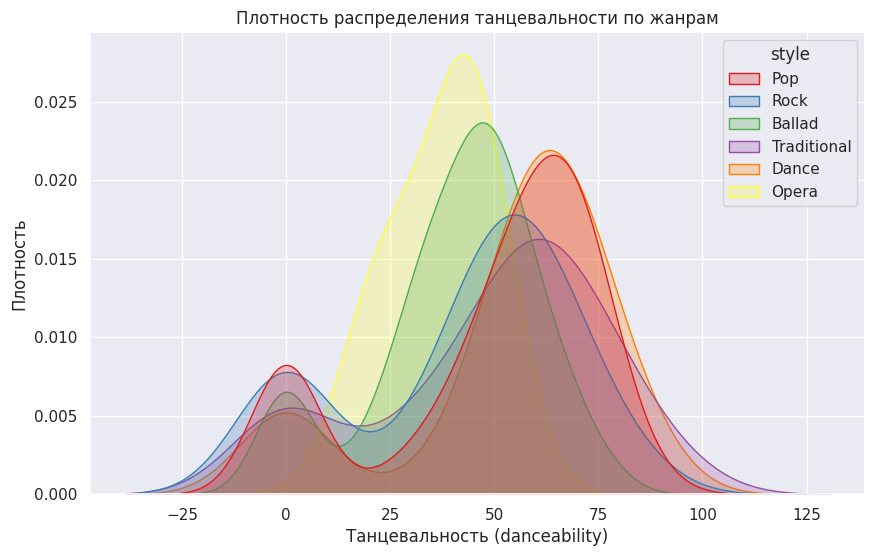

In [51]:
plt.figure(figsize=(10, 6))
sns.kdeplot(data=data, x='danceability', hue='style', fill=True, common_norm=False, palette='Set1')
plt.title('Плотность распределения танцевальности по жанрам')
plt.xlabel('Танцевальность (danceability)')
plt.ylabel('Плотность')
plt.show()

### Altair

In [54]:
# Фильтруем пропуски, если они есть
filtered_data = data[['danceability', 'style']].dropna()

# Ограничим количество жанров, если их слишком много — оставим, например, топ-10
top_styles = filtered_data['style'].value_counts().head(10).index
filtered_data = filtered_data[filtered_data['style'].isin(top_styles)]

# Строим график
chart = alt.Chart(filtered_data).transform_density(
    'danceability',
    as_=['danceability', 'density'],
    groupby=['style']
).mark_area(opacity=0.6).encode(
    x=alt.X('danceability:Q', title='Танцевальность (danceability)'),
    y=alt.Y('density:Q', title='Плотность'),
    color=alt.Color('style:N', title='Жанр')
).properties(
    title='Плотность распределения танцевальности по жанрам',
    width=700,
    height=400
)

chart

alt.Chart(...)

## Задание 8

Покажите на ящиковой диаграмме взяимосвязь позиции в финальном рейтинге со страной. Итоги каких стран похожи между собой?

### Seaborn

<ipython-input-90-94237b0cd613>:8: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




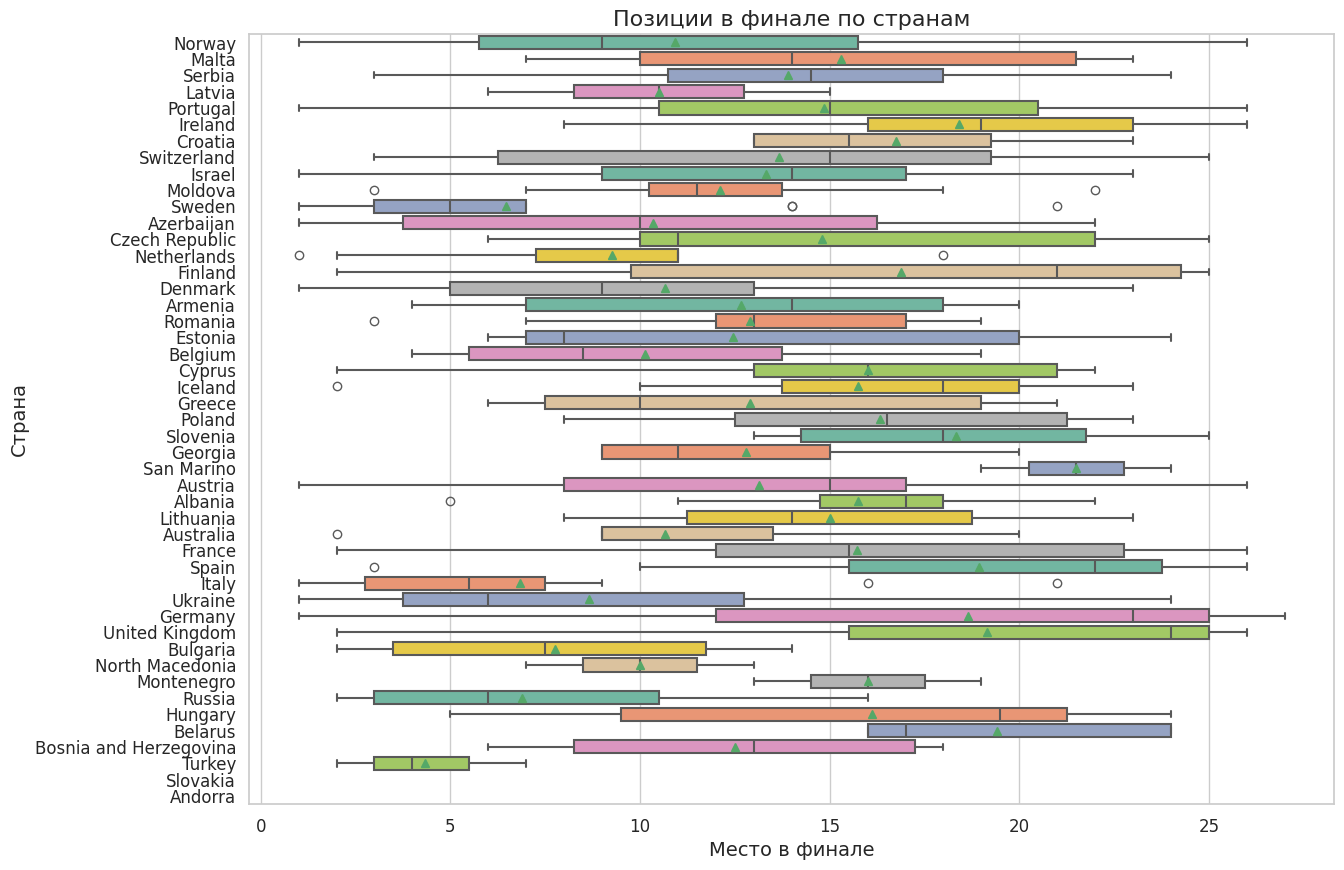

In [90]:
# Установим стиль seaborn
sns.set(style="whitegrid")

# Создаем график
plt.figure(figsize=(14, 10))  # Увеличим размер графика для лучшей читаемости

# Построение boxplot с добавлением средней линии и точек для выбросов
sns.boxplot(x='final_place', y='country', data=data, showmeans=True,
            palette="Set2", fliersize=6, linewidth=1.5)

# Настройка титулов и подписей
plt.title('Позиции в финале по странам', fontsize=16)
plt.xlabel('Место в финале', fontsize=14)
plt.ylabel('Страна', fontsize=14)

# Улучшение видимости
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# Показать график
plt.show()

### Plotly

In [103]:
fig = px.box(
    data,
    x='country',
    y='final_place',
    points='outliers',
    color='country'  # Можно убрать, если не хочешь цветовую группировку
)

fig.update_layout(
    title='Позиции в финале по странам (boxplot)',
    xaxis_title='Страна',
    yaxis_title='Место в финале',
    xaxis_tickangle=-45,
    height=600,
    width=900
)

fig.show()

## Задание 9

Покажите на карте количество раз, когда каждая страна датасета проходила в финал.

### Seaborn

--2025-04-23 14:03:59--  https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 838726 (819K) [text/plain]
Saving to: ‘world_map.geojson’

world_map.geojson   100%[===================>] 819.07K  --.-KB/s    in 0.04s   

2025-04-23 14:03:59 (22.6 MB/s) - ‘world_map.geojson’ saved [838726/838726]



<Figure size 3000x1000 with 0 Axes>

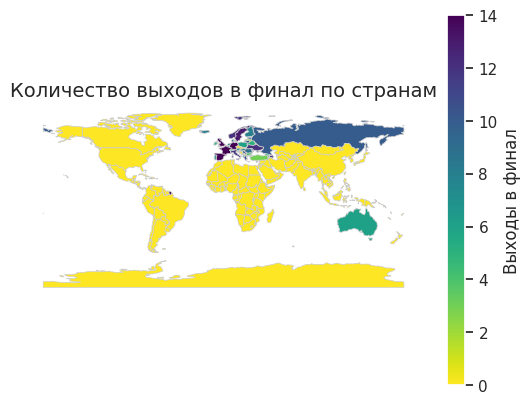

In [83]:
# Скачиваем карту вручную
!wget https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson -O world_map.geojson

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

# Загрузка данных
world = gpd.read_file("world_map.geojson")

# Загрузка нашего датасета
data = pd.read_csv("song_data.csv")
data['final_place'] = pd.to_numeric(data['final_place'], errors='coerce')

# Подсчёт финалов
finals_by_country = data[data['final_place'].notna() & (data['final_place'] != 0)]
finals_count = finals_by_country['country'].value_counts().reset_index()
finals_count.columns = ['country', 'finals_count']

# Объединение данных по странам
world_merged = world.merge(finals_count, how='left', left_on='NAME', right_on='country')
world_merged['finals_count'] = world_merged['finals_count'].fillna(0)

# Построение карты
plt.figure(figsize=(30, 10))
world_merged.plot(
    column='finals_count',
    cmap='viridis_r',  # Обратная палитра: 0 = светло-жёлтый, макс = тёмно-фиолетовый
    legend=True,
    legend_kwds={'label': "Выходы в финал"},
    edgecolor='0.8',
    linewidth=0.5,
    vmin=0  # Явно указываем минимум
)

plt.title('Количество выходов в финал по странам', fontsize=14)
plt.axis('off')
plt.show()

### Plotly

In [85]:
import plotly.express as px

fig = px.choropleth(
    finals_count,
    locations="country",
    locationmode="country names",
    color="finals_count",
    color_continuous_scale="Blues",
    title="Количество выходов в финал по странам (Plotly)",
)
fig.update_layout(geo=dict(showframe=False, showcoastlines=False))
fig.show()


## Задание 10

Покажите на диаграмме вида `treemap`, сколько раз каждая страна входила в топ-3 победителей.

*В `seaborn` нет такого типа графика, с помощью этого модуля строить график не нужно.*

### Plotly

In [89]:
# Создаём вспомогательные таблицы
finals_by_country = data[data['final_place'].notna()].groupby('country').size().reset_index(name='final_count')

top3 = data[data['final_place'].isin([1, 2, 3])]
top3_counts = top3['country'].value_counts().reset_index()
top3_counts.columns = ['country', 'top3_count']

finals_by_country.head(), top3_counts.head()

# сколько раз страна была в топ-3
top3 = data[data['final_place'].isin([1, 2, 3])]
top3_counts = top3['country'].value_counts().reset_index()
top3_counts.columns = ['country', 'top3_count']

fig = px.treemap(
    top3_counts,
    path=['country'],
    values='top3_count',
    title='Сколько раз страны входили в топ-3 финалистов'
)
fig.update_layout(height=600)
fig.show()

# Дополнительное задание

Постройте график рассеяния (scatter plot), отображающий взаимосвязь между BPM и loudness для жанров Pop и Rock. Добавьте тренд для каждого жанра. Выполните с помощью seaborn.

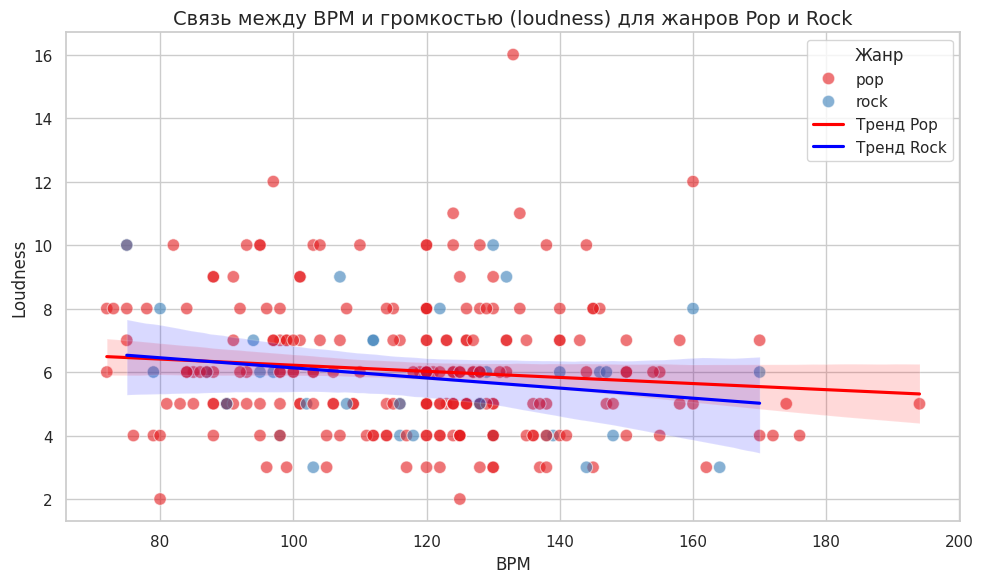

In [100]:
# Фильтрация по жанрам pop и rock
filtered_data = data[data['style'].isin(['pop', 'rock'])] #оставляем только строки с нужными стилями

# Построение графика
plt.figure(figsize=(10, 6))
#Строим диаграмму рассеяния
#alpha-прозрачность точек, s-размер точек, hue='style' — цвет зависит от жанра
sns.scatterplot(data=filtered_data, x='BPM', y='loudness', hue='style', palette='Set1', alpha=0.6, s=80)

#тренд линии
sns.regplot(data=filtered_data[filtered_data['style'] == 'pop'], x='BPM', y='loudness',
            scatter=False, color='red', label='Тренд Pop')
sns.regplot(data=filtered_data[filtered_data['style'] == 'rock'], x='BPM', y='loudness',
            scatter=False, color='blue', label='Тренд Rock')

# Подписи и оформление
plt.title('Связь между BPM и громкостью (loudness) для жанров Pop и Rock', fontsize=14)
plt.xlabel('BPM', fontsize=12)
plt.ylabel('Loudness', fontsize=12)
plt.legend(title='Жанр')
plt.tight_layout()
plt.show()


# Порядок защиты работы

**Для защиты работы необходимо:**
1. Предоставить результаты выполнения 10 заданий в виде ссылки на Google Colab.
2. Выполнить дополнительное задание в процессе сдачи работы. Дополнительное задание представляет собой построение визуализации по данным из лабораторной работы, по сложности аналогичной тем, что требовалось выполнить в рамках работы.

**Примеры дополнительных заданий:**
1. Покажите на ящиковой диаграмме распределение танцевальности для каждого жанра. Выполните с помощью `seaborn`.
2. На круговой диаграмме покажите исполнителей, которые участвовали больше одного раза и какие места они занимали. Выполните с помощью `plotly`.
3. Покажите на диаграмме вида `treemap`, сколько раз каждая страна проходила в финал. Выполните с помощью `plotly`.

# Дополнительные материалы

1. seaborn: statistical data visualization [Электронный ресурс]. URL: https://seaborn.pydata.org/ (дата обращения: 01.04.2024).
2. Plotly Open Source Graphing Libraries [Электронный ресурс]. URL: https://plotly.com/graphing-libraries/ (дата обращения: 01.04.2024).
3. Vega-Altair: Declarative Visualization in Python [Электронный ресурс]. URL: https://altair-viz.github.io/index.html (дата обращения: 01.04.2024).